In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

In [5]:
import warnings
warnings.filterwarnings("ignore")

In [6]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

In [7]:
df = pd.read_csv('C:\\Users\\user\\Desktop\\Nouveau dossier\\medical_insurance.csv')

In [8]:
df.shape

(2772, 7)

In [9]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [10]:
df.isna().sum()
#no missing values

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [11]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [12]:
df.duplicated().sum()
# to see if there are any duplicate rows in the dataset. If the sum is greater than 0, it means there are duplicate rows that may need to be removed.

np.int64(1435)

In [13]:
dup_counts=df.groupby(list(df.columns)).size().reset_index(name='count').sort_values(by='count', ascending=False)
# this line of code groups the DataFrame df by all its columns, counts the number of occurrences of each unique combination of values, and creates a new DataFrame dup_counts with the unique combinations and their corresponding counts. The resulting DataFrame is then sorted in descending order based on the count column, so that the most frequently occurring combinations appear first.

In [14]:
dup_counts["count"].value_counts()
# this line of code counts the number of occurrences of each unique value in the "count" column of the dup_counts DataFrame. It helps to identify how many duplicate rows exist and how many times they are repeated in the dataset.

count
2    1288
4      49
Name: count, dtype: int64

In [15]:
df=df.drop_duplicates().reset_index(drop=True)
# 

In [16]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1332,50,male,30.970,3,no,northwest,10600.54830
1333,18,female,31.920,0,no,northeast,2205.98080
1334,18,female,36.850,0,no,southeast,1629.83350
1335,21,female,25.800,0,no,southwest,2007.94500


In [17]:
for col in ['sex', 'smoker', 'region']:
     print(f"Unique values in '{col}': {df[col].unique()}")
     print(df[col].value_counts())
     print(df[col].value_counts(normalize=True))
     # with normalize=True, the value_counts() method returns the relative frequencies of each unique value in the column, rather than the absolute counts. This can be useful for understanding the distribution of values in a categorical variable, especially when comparing variables with different numbers of observations.

Unique values in 'sex': ['female' 'male']
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.504862
female    0.495138
Name: proportion, dtype: float64
Unique values in 'smoker': ['yes' 'no']
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795064
yes    0.204936
Name: proportion, dtype: float64
Unique values in 'region': ['southwest' 'southeast' 'northwest' 'northeast']
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272251
southwest    0.243082
northwest    0.242334
northeast    0.242334
Name: proportion, dtype: float64


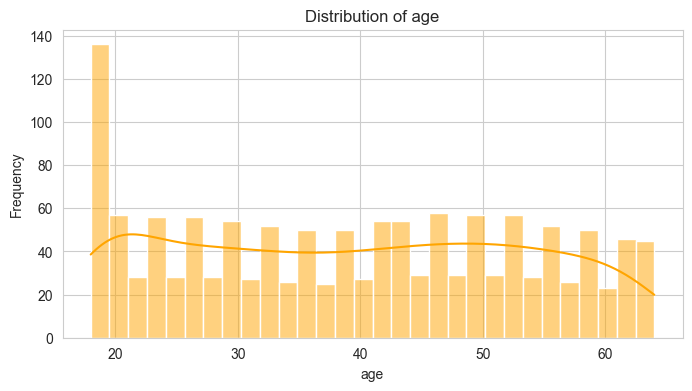

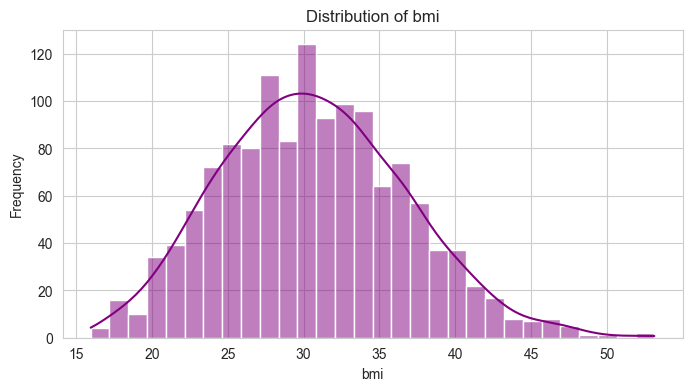

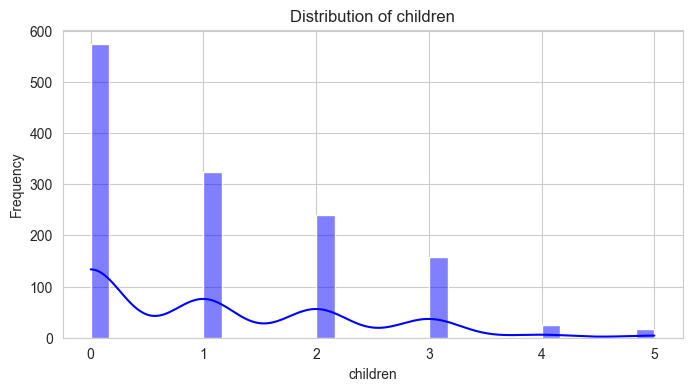

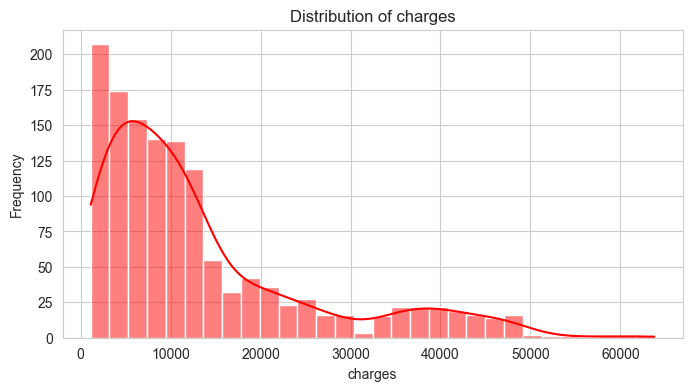

In [18]:
import random
for col in ["age", "bmi", "children", "charges"]:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30,color=random.choice(['blue', 'green', 'red', 'purple', 'orange']))
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

<Axes: xlabel='children', ylabel='charges'>

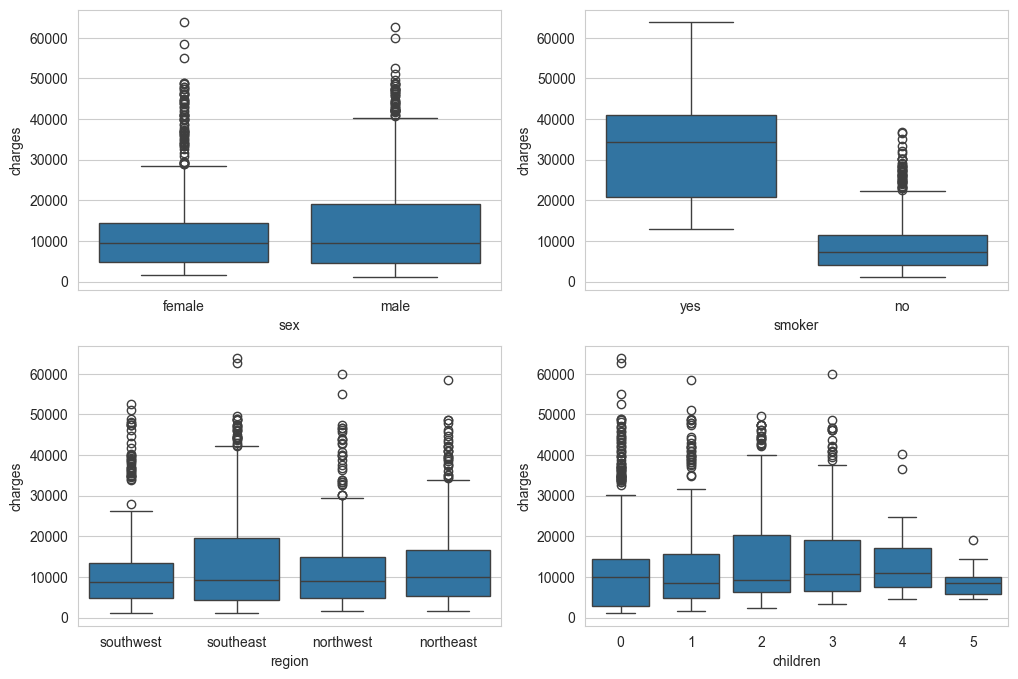

In [19]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
sns.boxplot(x='sex',y='charges',data=df,ax=axes[0,0])
sns.boxplot(x='smoker',y='charges',data=df,ax=axes[0,1])
sns.boxplot(x='region',y='charges',data=df,ax=axes[1,0])
sns.boxplot(x='children',y='charges',data=df,ax=axes[1,1])

In [20]:
for col in ["bmi","charges"]:
    q1,q3=df[col].quantile([0.25,0.75])
    # quantile
    igr=q3-q1
    lower,upper=q1-1.5*igr,q3+1.5*igr
    n_out=df[(df[col]<lower) | (df[col]>upper)].sum()
    print(f"Number of outliers in '{col}': {n_out}")
    

Number of outliers in 'bmi': age                                                       357
sex                malefemalemalefemalemalefemalemalemalemale
bmi                                                    443.49
children                                                    8
smoker                                  nononoyesnoyesyesnono
region      southeastnortheastsoutheastsoutheastsoutheasts...
charges                                          196633.93621
dtype: object
Number of outliers in 'charges': age                                                      5710
sex         malemalefemalemalemalemalemalemalemalemalemale...
bmi                                                   4943.48
children                                                  165
smoker      yesyesyesyesyesyesyesyesyesyesyesyesyesyesyesy...
region      southeastsouthwestnortheastsouthwestsouthwests...
charges                                         5852448.66161
dtype: object


In [21]:
df.groupby('smoker')['charges'].agg(['mean', 'median', 'std'])

,mean,median,std
smoker,,,
no,8440.660307,7345.72660,5992.973800
yes,32050.231832,34456.34845,11541.547176


In [22]:
def bmi_category(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif 18.5 <= bmi < 25:
        return 'Normal weight'
    elif 25 <= bmi < 30:
        return 'Overweight'
    else:
        return 'Obesity'

In [23]:
df['bmi_category'] = df['bmi'].apply(bmi_category)
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,Obesity
2,28,male,33.000,3,no,southeast,4449.46200,Obesity
3,33,male,22.705,0,no,northwest,21984.47061,Normal weight
4,32,male,28.880,0,no,northwest,3866.85520,Overweight


In [24]:
df["log_charges"] = np.log(df["charges"])

In [25]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,Overweight,9.734176
1,18,male,33.770,1,no,southeast,1725.55230,Obesity,7.453302
2,28,male,33.000,3,no,southeast,4449.46200,Obesity,8.400538
3,33,male,22.705,0,no,northwest,21984.47061,Normal weight,9.998092
4,32,male,28.880,0,no,northwest,3866.85520,Overweight,8.260197


In [26]:
df["charges"].skew()
# skewness is a measure of the asymmetry of the probability distribution of a real-valued random variable about its mean. A positive skew indicates that the tail on the right side of the distribution is longer or fatter than the left side, while a negative skew indicates that the tail on the left side is longer or fatter than the right side. A skewness value close to 0 suggests a symmetric distribution.

np.float64(1.5153909108403483)

In [27]:
df_model = pd.get_dummies(
    df,
    columns=["sex", "smoker", "bmi_category", "region"],
    drop_first=True
)
# get_dummies is a method in pandas that converts categorical variables into dummy/indicator variables.
# It creates new binary columns for each category of the categorical variable, where 1 indicates the presence
# of that category and 0 indicates its absence. This is useful for machine learning models that require numerical input.
print(df_model.columns.to_list())
# get dumies is a method in pandas that converts categorical variables into dummy/indicator variables. It creates new binary columns for each category of the categorical variable, where 1 indicates the presence of that category and 0 indicates its absence. This is useful for machine learning models that require numerical input.
df_model.head()

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'bmi_category_Obesity', 'bmi_category_Overweight', 'bmi_category_Underweight', 'region_northwest', 'region_southeast', 'region_southwest']


,age,bmi,children,charges,log_charges,sex_male,smoker_yes,bmi_category_Obesity,bmi_category_Overweight,bmi_category_Underweight,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,9.734176,False,True,False,True,False,False,False,True
1,18,33.770,1,1725.55230,7.453302,True,False,True,False,False,False,True,False
2,28,33.000,3,4449.46200,8.400538,True,False,True,False,False,False,True,False
3,33,22.705,0,21984.47061,9.998092,True,False,False,False,False,True,False,False
4,32,28.880,0,3866.85520,8.260197,True,False,False,True,False,True,False,False


In [28]:
feature_cols=[c for c in df_model.columns if c not in ["charges","log_charges"]]
X=df_model[feature_cols]
y=df_model["log_charges"]

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

y_test_real = np.expm1(y_test)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
}

trained_models = {}
metrics_rows = []

for name, model in candidate_models.items():
    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    
    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred))
    
    trained_models[name] = model
    metrics_rows.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})
    print(f"{name} - R2: {r2:.4f}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")

Linear Regression - R2: 0.5118, MAE: 4105.1650, RMSE: 7753.7253
Random Forest - R2: 0.7997, MAE: 2482.0793, RMSE: 4966.6009
Gradient Boosting - R2: 0.8094, MAE: 2285.7844, RMSE: 4845.4041


In [31]:
results= pd.DataFrame(metrics_rows).sort_values(by="R2",ascending=False).reset_index(drop=True)


In [32]:
best_model_name=results.loc[0]["Model"]
best_model=trained_models[best_model_name]


In [33]:
best_model_name

'Gradient Boosting'

In [ ]:
joblib.dump(best_model, 'insurance_model.pkl')
#pkl binary file
#joblib is a library used for serializing and deserializing Python objects, allowing you to save and load models or other data structures efficiently. The 'insurance_model.pkl' file will contain the trained model that can be loaded later for predictions.
joblib.dump(feature_cols, 'feature_columns.pkl')
joblib.dump(best_model, 'model_name.pkl')
#Production / Deployment: These .pkl files are the ones integrated into a web application
#  (using Streamlit, Flask, or FastAPI) to allow users to input data and get live predictions of insurance costs.

['model_name.pkl']